# WY2021 bulk snow density at five Juneau Icefield pit sites

Compare the archived July 2021 snow pits at DG1, TKG4, TKG3, TKG2, and C161 with the two SNOWPACK forcing variants. Run with the **JIF snow modeling** kernel.

Pit bulk density is adjusted SWE divided by pit depth in meters. Model bulk density is hourly `SWE / HS_mod`, using SWE in kg/m² and modeled depth in meters. The pit ratio describes seasonal snow, while the model ratio describes the entire snow/firn column. These are descriptive comparisons across different layers. A seasonal model density would require identifying the 2020/21 horizon in the layer profiles and integrating mass and thickness above it.

Compare the model on the archived density sampling day using UTC model hours. TKG4 combines depth measured July 7 with SWE from the July 8 density sampling. TKG3 uses the archived July 9 date. Observation times and timezones are unrecorded. Pit metadata flags are included in the audit.

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'sites/radar_sites/scripts/compare_model_pit_radar.py').is_file()), None)
if root is None:
    raise RuntimeError('Open this notebook from inside jif_snow_modeling')
sys.path.insert(0, str(root / 'sites/radar_sites/scripts'))

from compare_model_pit_radar import FORCINGS, load_models, load_pits
from visualization import (OBSERVATION_COLOR, OBSERVATION_MARKERS, RC_PARAMS,
                           SIMULATION_COLORS, SIMULATION_LABELS)

plt.rcParams.update(RC_PARAMS)
pits = load_pits().sort_values('elevation_m')
models, run_audit = load_models()


## Pit density and sampling-day model comparisons

The model value is the mean of the 24 hourly density ratios on each pit’s sampling day. Report a daily mean only when all 24 ratios are defined. Positive differences indicate higher modeled density. Raw TKG4 and DG1 use the [documented numerical guard](../numerics/README.md).

In [2]:
pits['pit_density_kg_m3'] = pits.swe_mm / (pits.depth_cm / 100).where(pits.depth_cm > 0)
model_density = {
    key: frame.swe_mm.where(frame.swe_mm >= 0) / (frame.depth_cm / 100).where(frame.depth_cm > 0)
    for key, frame in models.items()
}

rows = []
for site, pit in pits.iterrows():
    day = pd.date_range(pit.pit_swe_date, periods=24, freq='h')
    for forcing in FORCINGS:
        density = model_density[site, forcing].reindex(day)
        mean = density.mean() if density.count() == len(day) else float('nan')
        rows.append({
            'site': site.upper(),
            'forcing': SIMULATION_LABELS[forcing],
            'sampling_day': pit.pit_swe_date.date(),
            'valid_hours': density.count(),
            'pit_density_kg_m3': pit.pit_density_kg_m3,
            'model_density_kg_m3': mean,
            'model_minus_pit_kg_m3': mean - pit.pit_density_kg_m3,
        })

comparison = pd.DataFrame(rows)
pit_columns = ['pit_date', 'pit_swe_date', 'depth_cm', 'swe_mm', 'pit_density_kg_m3', 'quality_flags']
display(pits[pit_columns].round(1))
display(comparison.round(1))


,pit_date,pit_swe_date,depth_cm,swe_mm,pit_density_kg_m3,quality_flags
site,,,,,,
dg1,2021-07-10,2021-07-10,315.0,1759.4,558.5,
tkg4,2021-07-07,2021-07-08,378.0,2014.3,532.9,archived_pit_date_differs_from_paper_table1_gt...
tkg3,2021-07-09,2021-07-09,378.0,2110.3,558.3,archived_pit_date_differs_from_paper_table1_gt...
tkg2,2021-07-15,2021-07-15,360.0,2086.1,579.5,
c161,2021-07-15,2021-07-15,473.0,2776.8,587.1,


,site,forcing,sampling_day,valid_hours,pit_density_kg_m3,model_density_kg_m3,model_minus_pit_kg_m3
0,DG1,HRRR-AK Raw,2021-07-10,24,558.5,553.6,-4.9
1,DG1,HRRR-AK Lapserate,2021-07-10,24,558.5,555.9,-2.7
2,TKG4,HRRR-AK Raw,2021-07-08,24,532.9,523.3,-9.6
3,TKG4,HRRR-AK Lapserate,2021-07-08,24,532.9,538.8,5.9
4,TKG3,HRRR-AK Raw,2021-07-09,24,558.3,545.8,-12.5
5,TKG3,HRRR-AK Lapserate,2021-07-09,24,558.3,540.7,-17.5
6,TKG2,HRRR-AK Raw,2021-07-15,24,579.5,549.7,-29.8
7,TKG2,HRRR-AK Lapserate,2021-07-15,24,579.5,549.8,-29.6
8,C161,HRRR-AK Raw,2021-07-15,24,587.1,563.1,-23.9
9,C161,HRRR-AK Lapserate,2021-07-15,24,587.1,565.0,-22.1


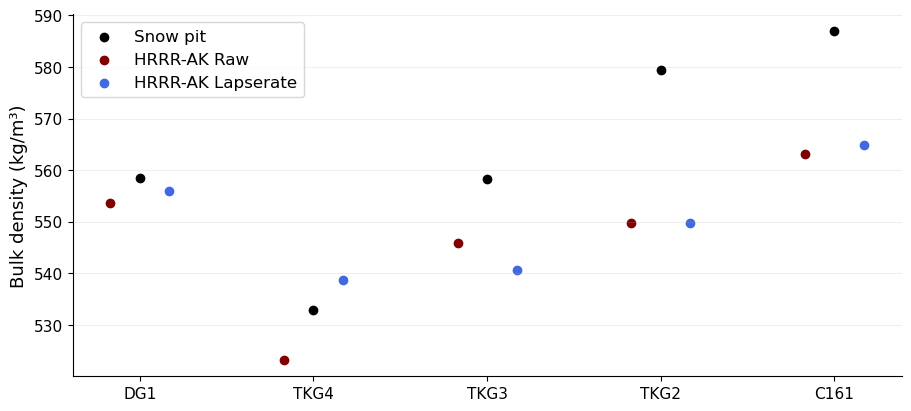

In [3]:
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
sites = pits.index.str.upper()
ax.scatter(range(len(sites)), pits.pit_density_kg_m3, color=OBSERVATION_COLOR,
           marker=OBSERVATION_MARKERS['pit'], label='Snow pit', zorder=3)
for offset, forcing in zip((-0.17, 0.17), FORCINGS):
    label = SIMULATION_LABELS[forcing]
    values = comparison.loc[comparison.forcing.eq(label), 'model_density_kg_m3']
    ax.scatter([i + offset for i in range(len(sites))], values,
               color=SIMULATION_COLORS[forcing], label=label)
ax.set(xticks=range(len(sites)), xticklabels=sites, ylabel='Bulk density (kg/m³)')
ax.grid(axis='y', alpha=.2)
ax.legend()
plt.show()


## Hourly density around the sampling days

All panels cover the same July window. The black point is centered on the sampling day for display. The shaded band spans that UTC day.

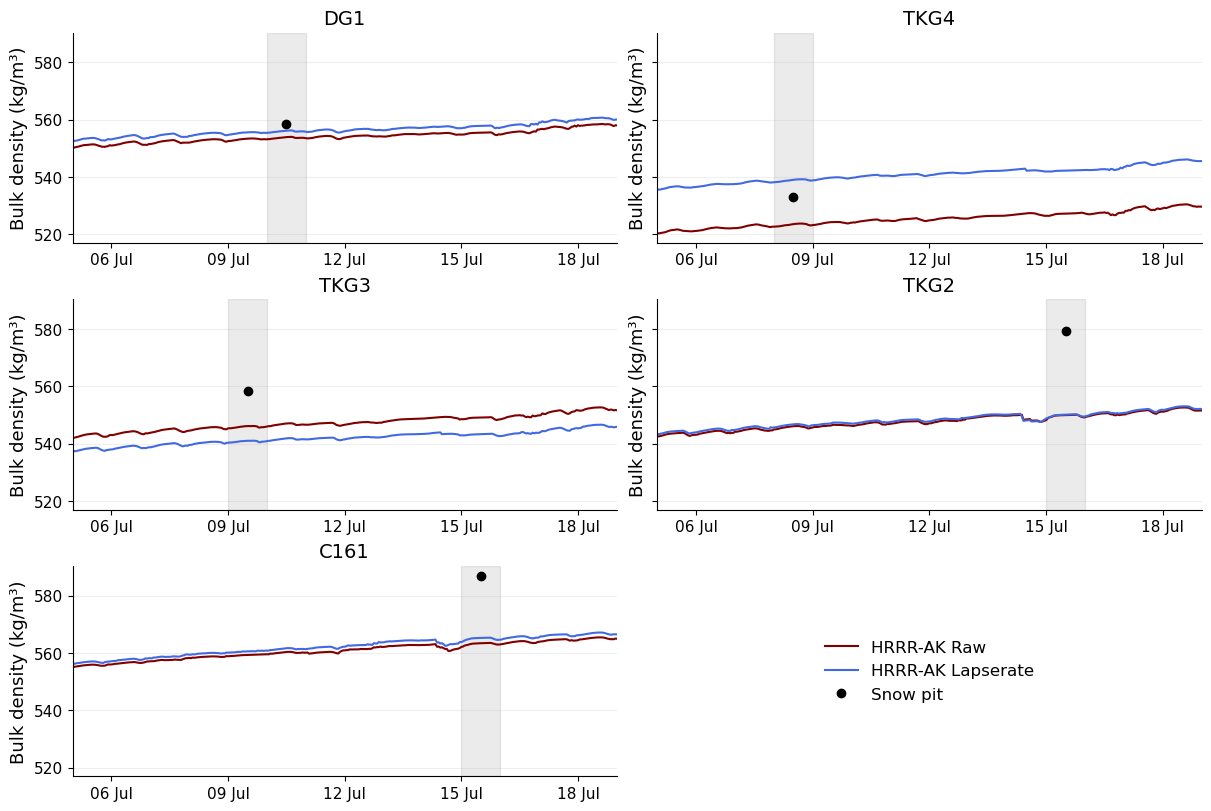

In [4]:
padding = pd.Timedelta(days=3)
start = pits.pit_swe_date.min() - padding
end = pits.pit_swe_date.max() + pd.Timedelta(days=1) + padding
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, sharey=True, layout='constrained')
for ax, (site, pit) in zip(axes.flat, pits.iterrows()):
    day = pit.pit_swe_date
    ax.axvspan(day, day + pd.Timedelta(days=1), color=OBSERVATION_COLOR, alpha=.08)
    for forcing in FORCINGS:
        density = model_density[site, forcing].loc[start:end]
        ax.plot(density.index, density, color=SIMULATION_COLORS[forcing])
    ax.scatter(day + pd.Timedelta(hours=12), pit.pit_density_kg_m3,
               color=OBSERVATION_COLOR, marker=OBSERVATION_MARKERS['pit'], zorder=3)
    ax.set(title=site.upper(), ylabel='Bulk density (kg/m³)', xlim=(start, end))
    ax.tick_params(axis='x', labelbottom=True)
    ax.grid(axis='y', alpha=.2)

date_axis = axes.flat[0].xaxis
date_axis.set_major_locator(mdates.DayLocator(interval=3))
date_axis.set_major_formatter(mdates.DateFormatter('%d %b'))
legend_ax = axes.flat[-1]
legend_ax.set_axis_off()
handles = [Line2D([], [], color=SIMULATION_COLORS[f], label=SIMULATION_LABELS[f]) for f in FORCINGS]
handles.append(Line2D([], [], color=OBSERVATION_COLOR, marker=OBSERVATION_MARKERS['pit'],
                      linestyle='', label='Snow pit'))
legend_ax.legend(handles=handles, loc='center', frameon=False)
plt.show()
